# Solar Site Identification Tool v0.1
Goals: lets run a site search for camberwell. filtering by roof size.

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
import xyzservices.providers as xyz
import numpy as np
from branca.colormap import linear
import dash


c:\Users\odhra\OneDrive\Documents\Work\CES\solar project\London-Solar-Map\.solar_venv\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'osopentoid_202611_tq.gpkg': 'os_mastermap_topography_layer' (default), 'os_mastermap_sites_layer', 'os_mastermap_highways_network'. Specify layer parameter to avoid this warning.
  result = read_func(


Loaded 3,026,538 features


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

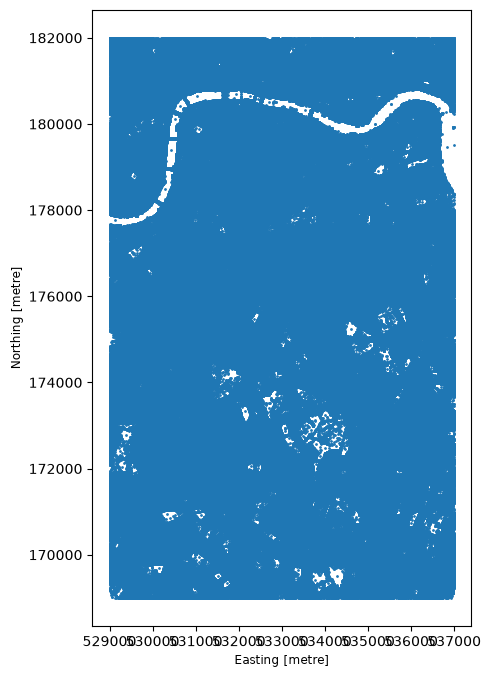

In [ ]:
# Bounding around southwark

path = "osopentoid_202611_gpkg_tq\osopentoid_202611_tq.gpkg"

# British National Grid: min easting, min northing, max easting, max northing
bbox = (529000, 169000, 537000, 182000)

southwark = gpd.read_file(path, bbox=bbox)

print(f"Loaded {len(southwark):,} features")
southwark.plot(figsize=(8, 8), markersize=1)

lsom = pd.read_csv(
    "LSOM/LSOM_by_TOID.csv",
    dtype={"fid_topo": "string"}
)

southwark["TOID"] = southwark["TOID"].astype("string").str.strip()
lsom["fid_topo"] = lsom["fid_topo"].str.strip()

sites = southwark.merge(
    lsom,
    left_on="TOID",
    right_on="fid_topo",
    how="inner"
)

print(f"Matched rows: {len(sites):,}")

sites.to_file("Southwark/southwark_joined_solar.gpkg", driver="GPKG")

We've joined the OS and Solar maps. Now to start filtering by roof size.

In [2]:
southwark = gpd.read_file("Southwark/southwark_joined_solar.gpkg")

In [4]:
candidates_m2_kwh = southwark[
    (southwark["area3d_in_potential"] >= 300)
    & (southwark["sum_total_potential"] >= 30000)
].copy()

candidates_m2_kwh.head(10)

,TOID,VERSION_NUMBER,VERSION_DATE,EASTING,NORTHING,fid_topo,avg_potential_m2_viable,area3d_in_potential,sum_total_potential,avg_tilt,lidar_date,geometry
118,osgb1000001769537684,3,2017-08-08,534914.8125,170121.312500,osgb1000001769537684,937.709263,633.5246,5.940619e+05,18.603237,2015.0,POINT (534914.832 170121.317)
136,osgb1000006145437,4,2017-08-08,534945.7500,170028.343750,osgb1000006145437,922.725300,304.2496,2.807388e+05,29.885600,2015.0,POINT (534945.72 170028.342)
338,osgb1000041661108,8,2017-10-20,535596.8750,169982.125000,osgb1000041661108,966.721151,3142.2378,3.037668e+06,9.685076,2012.0,POINT (535596.864 169982.12)
340,osgb1000041661427,9,2026-09-10,535481.4375,170171.531250,osgb1000041661427,939.816600,2186.2380,2.054663e+06,9.026409,2012.0,POINT (535481.413 170171.538)
417,osgb1000041657474,5,2025-07-01,535392.1875,169966.531250,osgb1000041657474,924.882600,743.8913,6.880121e+05,18.146130,2012.0,POINT (535392.192 169966.533)
426,osgb1000041657476,5,2017-08-08,535366.3125,169937.375000,osgb1000041657476,885.501365,800.2389,7.086126e+05,24.638718,2012.0,POINT (535366.33 169937.38)
429,osgb1000041657635,3,2006-02-19,535381.5000,169953.187500,osgb1000041657635,915.004717,543.4770,4.972840e+05,17.933910,2012.0,POINT (535381.503 169953.183)
476,osgb1000041661978,4,2017-08-08,535188.3125,170079.968750,osgb1000041661978,915.141019,465.2302,4.257512e+05,25.309332,2012.0,POINT (535188.299 170079.974)
581,osgb1000006146587,4,2004-12-22,534395.8125,170163.625000,osgb1000006146587,870.677000,509.7954,4.438671e+05,9.964002,2015.0,POINT (534395.791 170163.628)
582,osgb1000006146586,3,2004-01-10,534421.0000,170143.453125,osgb1000006146586,839.087704,388.1440,3.256869e+05,9.492746,2015.0,POINT (534421 170143.45)


In [5]:


# Create a map with a faded background
m = folium.Map(tiles=None)

folium.TileLayer(
    tiles="OpenStreetMap",
    opacity=0.3,
).add_to(m)

# Add prominent candidate buildings
candidates_m2_kwh.explore(
    m=m,
    color="#e60073",
    tooltip=True,
    style_kwds={
        "color": "#55002b",
        "weight": 2,
        "fillOpacity": 0.9,
    },
    highlight_kwds={
        "weight": 4,
        "fillOpacity": 1,
    },
)

m.fit_bounds(candidates_m2_kwh.to_crs(4326).total_bounds.reshape(2, 2)[:, ::-1].tolist())

m

In [ ]:
AREA_MIN = 300
AREA_MAX = 2_000
POTENTIAL_MIN = 30_000
POTENTIAL_MAX = 2_000_000

# Prepare a point inside each building
dots = candidates_m2_kwh.to_crs(epsg=4326).copy()
dots = dots.dropna(
    subset=["geometry", "area3d_in_potential", "sum_total_potential"]
)
dots = dots.loc[~dots.geometry.is_empty].copy()

if dots.empty:
    raise ValueError("No valid candidates to plot.")

dots["geometry"] = dots.geometry.representative_point()

# Cap display values without changing the original data
dots["radius_px"] = 5 * np.sqrt(
    dots["area3d_in_potential"].clip(AREA_MIN, AREA_MAX) / AREA_MIN
)
dots["potential_display"] = dots["sum_total_potential"].clip(
    POTENTIAL_MIN, POTENTIAL_MAX
)

colours = linear.YlOrRd_09.scale(POTENTIAL_MIN, POTENTIAL_MAX)
colours.caption = "Potential (raw LSOM) — darkest colour = 2,000,000+"

# Start directly over the candidates
west, south, east, north = dots.total_bounds

m = folium.Map(
    location=[(south + north) / 2, (west + east) / 2],
    zoom_start=13,
    tiles=None,
    prefer_canvas=True,
    height=650,
)

folium.TileLayer(
    tiles=xyz.Esri.WorldImagery,
    name="Satellite imagery",
    max_zoom=19,
).add_to(m)

# Smaller dots drawn last so they remain visible
for _, row in dots.sort_values(
    "area3d_in_potential", ascending=False
).iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=float(row["radius_px"]),
        color="white",
        weight=1,
        fill=True,
        fill_color=colours(float(row["potential_display"])),
        fill_opacity=0.9,
        tooltip=(
            f"Roof area: {row['area3d_in_potential']:,.0f} m²"
            f"<br>Potential: {row['sum_total_potential']:,.0f}"
        ),
    ).add_to(m)

colours.add_to(m)

m

In [19]:
m

In [31]:
%pip install dash

     ---------------------------------------- 0.0/137.6 kB ? eta -:--:--
     ---------------------------- --------- 102.4/137.6 kB 2.0 MB/s eta 0:00:01
     -------------------------------------- 137.6/137.6 kB 2.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.4/9.3 MB 8.1 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.3 MB 18.8 MB/s eta 0:00:01
   --------------------- ------------------ 5.0/9.3 MB 40.0 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 50.5 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 45.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/103.4 kB ? eta -:--:--
   ---------------------------------------- 103.4/103.4 kB ? eta 0:00:00
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ------------------- -------------------- 4.6/9.7 MB 149.3 MB/s eta 0:00:01
   --------------------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
from dash import Dash, html
import dash_leaflet as dl

# Centre the map over your candidate buildings
west, south, east, north = candidates_m2_kwh.to_crs(4326).total_bounds

app = Dash(__name__)

app.layout = html.Div([
    html.H2("Community Energy — Site Screening"),

    dl.Map(
        children=[
            dl.TileLayer(
                url=(
                    "https://server.arcgisonline.com/ArcGIS/rest/services/"
                    "World_Imagery/MapServer/tile/{z}/{y}/{x}"
                ),
                attribution="Esri World Imagery",
                maxZoom=19,
            ),
        ],
        center=[(south + north) / 2, (west + east) / 2],
        zoom=13,
        style={"height": "75vh", "width": "100%"},
    ),
])

app.run(jupyter_mode="external", debug=True)

Dash app running on http://127.0.0.1:8050/


In [34]:
%pip install dash-leaflet

     ---------------------------------------- 0.0/42.7 kB ? eta -:--:--
     ---------------------------- ----------- 30.7/42.7 kB 1.3 MB/s eta 0:00:01
     ---------------------------------------- 42.7/42.7 kB 1.0 MB/s eta 0:00:00
     ---------------------------------------- 0.0/53.4 kB ? eta -:--:--
     ---------------------------------------- 53.4/53.4 kB 2.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/294.6 kB ? eta -:--:--
   --------------- ------------------------ 112.6/294.6 kB 3.2 MB/s eta 0:00:01
   ---------------------------------------- 294.6/294.6 kB 3.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ------------------------------ --------- 0.8/1.0 MB 16.3 MB/s eta 0:00:01
   ---------------------------------------- 1.0/1.0 MB 16.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/456.5 kB ? eta -:--:--
   --------------------------------------- 456.5/456.5 kB 29.8 MB/s eta 0:00:00
   --------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
